In [1]:
%pip install contextily

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [contextily]
Note: you may need to restart the kernel to use updated packages.


Pakiri: NZCCD line 4.0 km, map 4.7 x 5.9 km
Muriwai: NZCCD line 4.4 km, map 5.9 x 7.4 km
Pakiri: tile level 14
Muriwai: tile level 14
Saved to /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Figures


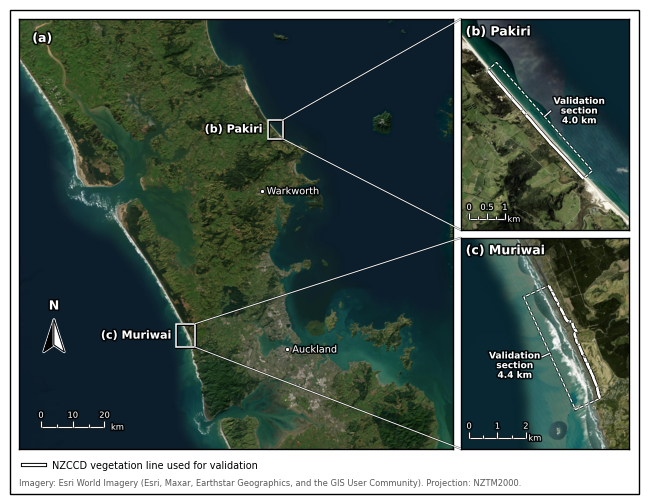

In [2]:
# =====================================================================================
# Validation site figure: context map + one satellite-imagery map per validation site
# =====================================================================================
# (a) Upper North Island, with a box showing where each site panel sits
# (b), (c) Each site: the NZCCD reference line, a box around its extent, and the surrounding area
#
# Basemap: Esri World Imagery by default, or LINZ Basemaps aerial imagery if you add a LINZ API key.
# Everything is drawn in NZTM2000 (EPSG:2193), so the scale bars are true metres.
# Needs: geopandas, matplotlib, pyproj, contextily (pip install contextily), and internet for tiles.
# Saves validation_sites.png (DPI below) and validation_sites.pdf to OUT.

import os
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.transforms as mtransforms
from matplotlib.patches import Rectangle, ConnectionPatch
from matplotlib.lines import Line2D
from pyproj import Transformer
import contextily as ctx

# ---------------- EDIT ME ----------------
DATA_CANDIDATES = [   # the first folder that exists is used, so this runs on either computer
    r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data',
    '/Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data',
]
DATA = next((p for p in DATA_CANDIDATES if os.path.isdir(p)), DATA_CANDIDATES[0])
NZL = os.path.join(DATA, 'NZCCD_Validation_Lines')
OUT = os.path.join(DATA, 'Figures')

# Sites in panel order (top, bottom).
#   line    the NZCCD line used for validation
#   extra   optional: the rest of the NZCCD line, drawn faint and dashed (None to leave it off),
#           e.g. os.path.join(NZL, 'Pakiri', 'Pakiri_NZCCD_2023_isolated.shp')
#   extent  area the site map must show (lon_min, lat_min, lon_max, lat_max); it is widened or
#           heightened to fit SITE_ASPECT. None = fit to the NZCCD line using SITE_ZOOM_OUT
#           (wider views used earlier: Pakiri (174.62, -36.33, 174.82, -36.12),
#            Muriwai (174.32, -36.90, 174.50, -36.73))
#   sea     a point well out at sea (lat, lon), so the bracket goes on the seaward side
#   gap     bracket distance from the line, as a fraction of map width (None = BRACKET_GAP)
#   label_at  where the label tick sits along the bracket: 0 = north end, 0.5 = middle, 1 = south end
#   label_va  'center' = tick points at the middle of the label; 'top' = tick meets its top line and
#             the label hangs below (use where there's no room beside the bracket)
SITES = {
    'Pakiri':  {'line':   os.path.join(NZL, 'Pakiri', 'Pakiri_NZCCD_2023_clipped.shp'),
                'extra':  None,
                'extent': None,
                'sea':    (-36.22, 174.85),
                'gap': None, 'label_at': 0.5, 'label_va': 'center'},
    'Muriwai': {'line':   os.path.join(NZL, 'Muriwai', 'Muriwai_2022_NZCCD.shp'),
                'extra':  None,
                'extent': None,
                'sea':    (-36.82, 174.30),
                'gap': 0.16, 'label_at': 0.5, 'label_va': 'top'},   # clear of the surf zone
}

# Bracket beside each validation line (sizes are fractions of the site map's width)
BRACKET = True
BRACKET_GAP = 0.07     # gap between the line and the bracket
BRACKET_TOUCH = 0.012  # gap left between each end hook and the end of the line
BRACKET_MID = 0.05     # length of the tick from the bracket to the label
BRACKET_LABEL = 'Validation\nsection\n{km:.1f} km'   # {km} = length of the validation line
BRACKET_FONT = 6.5                                       # label font size (pt)
CENTRE_ON_LINE = True   # keep each extent's size but move it so the NZCCD box sits in the middle

# Context map extent (lon_min, lat_min, lon_max, lat_max), centred between the two sites
CONTEXT = (173.82, -37.12, 175.32, -35.92)
PLACES = {'Auckland': (-36.848, 174.763), 'Warkworth': (-36.400, 174.663)}
# name: (lat, lon); {} for none. Places near an edge or inside a site box are skipped

BOX_PAD = 300        # m of margin around the NZCCD line
SITE_ZOOM_OUT = 1.3  # only for sites with extent None: map size = this x the line's longest side (+ margin)
SHOW_BOX = False     # dashed box around the NZCCD line on the site maps
SITE_ASPECT = 1.25   # site panel height / width (1 = square; >1 = taller than wide)
CONNECT = True       # lines joining each context box to its site panel
BORDER = 1.0         # pt; border around each map and around the whole figure (0 for none)

BASEMAP = 'esri'     # 'esri' or 'linz'
LINZ_KEY = ''        # LINZ Basemaps API key, only needed for BASEMAP = 'linz'
ZOOM = {'context': 'auto', 'site': 'auto'}   # 'auto' = enough detail for DPI; or a tile level, e.g. 15
MAX_ZOOM = 17        # cap for 'auto' (each level up is 4x the tiles to download)

FIG_WIDTH = 6.3      # in (16 cm, a typical thesis text width)
DPI = 300
FONT = 8
# ------------------------------------------

LINE_COL, BOX_COL = 'white', 'white'
HALO = [pe.withStroke(linewidth=2.2, foreground='black', alpha=0.85)]
TO_NZTM = Transformer.from_crs(4326, 2193, always_xy=True)
plt.rcParams.update({'font.size': FONT, 'font.family': 'sans-serif'})

if BASEMAP == 'linz':
    if not LINZ_KEY:
        raise ValueError('Set LINZ_KEY to use the LINZ basemap, or set BASEMAP = "esri".')
    SOURCE = ('https://basemaps.linz.govt.nz/v1/tiles/aerial/WebMercatorQuad/{z}/{x}/{y}.webp?api='
              + LINZ_KEY)
    CREDIT = 'Imagery: LINZ Basemaps aerial imagery (CC BY 4.0). Projection: NZTM2000.'
else:
    SOURCE = ctx.providers.Esri.WorldImagery
    CREDIT = ('Imagery: Esri World Imagery (Esri, Maxar, Earthstar Geographics, and the GIS User Community). '
              'Projection: NZTM2000.')


def short_path(p):
    '''Windows 8.3 short path, so GDAL can open files on long OneDrive paths. No change elsewhere.'''
    if os.name != 'nt':
        return p
    import ctypes
    buf = ctypes.create_unicode_buffer(1024)
    n = ctypes.windll.kernel32.GetShortPathNameW(p, buf, 1024)
    return buf.value if 0 < n < 1024 else p


def load(path):
    if not os.path.exists(path):
        raise FileNotFoundError(path)
    g = gpd.read_file(short_path(path))
    if g.crs is None:
        raise ValueError(f'{path} has no CRS set')
    return g.to_crs(2193)


def fit_aspect(b, aspect, min_w=0):
    '''Grow bounds b (x0, y0, x1, y1) about their centre to height/width = aspect.'''
    cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
    w = max(b[2] - b[0], (b[3] - b[1]) / aspect, min_w)
    h = w * aspect
    return (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)


def nice(x):
    '''Largest 1, 2 or 5 x 10^n not above x.'''
    e = 10 ** np.floor(np.log10(x))
    return next(m * e for m in (5, 2, 1) if m * e <= x)


def ax_size_in(ax):
    '''Width and height of an axes in inches.'''
    b = ax.get_position()
    w, h = ax.figure.get_size_inches()
    return b.width * w, b.height * h


def scalebar(ax, frac=0.3, x=0.05, y=0.05):
    '''Esri "Scale Line 1" style: a line with ticks at 0, the quarters and the end, labels above.'''
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    L = nice((x1 - x0) * frac)
    bx, by = x0 + x * (x1 - x0), y0 + y * (y1 - y0)
    _, h_in = ax_size_in(ax)
    big, small = 0.06 / h_in * (y1 - y0), 0.035 / h_in * (y1 - y0)   # tick heights: 0.06 in, 0.035 in
    halo = [pe.withStroke(linewidth=2.2, foreground='black', alpha=0.85)]
    kw = dict(color='white', lw=0.9, solid_capstyle='butt', zorder=6, path_effects=halo)
    ax.plot([bx, bx + L], [by, by], **kw)
    for t in (0, 0.25, 0.5, 0.75, 1):
        ax.plot([bx + t * L] * 2, [by, by + (big if t in (0, 0.5, 1) else small)], **kw)
    unit, k = ('km', 1000) if L >= 1000 else ('m', 1)
    for t in (0, 0.5, 1):
        ax.text(bx + t * L, by + big * 1.25, f'{t * L / k:g}', ha='center', va='bottom', color='white',
                fontsize=FONT - 2, path_effects=HALO, zorder=6)
    ax.text(bx + L + 0.015 * (x1 - x0), by, unit, ha='left', va='center', color='white',
            fontsize=FONT - 2, path_effects=HALO, zorder=6)


def north_arrow(ax, x=0.08, y=0.30, size=0.32):
    '''ArcGIS "North 3" style: a split arrowhead, left half black and right half white, N above.
    x, y = axes position of the arrow tip; size = arrow height in inches.'''
    w_in, h_in = ax_size_in(ax)
    hy = size / h_in                         # height in axes units
    hx = 0.32 * size / w_in                  # half-width in axes units
    notch = 0.22 * hy                        # depth of the notch in the base
    tip, base_c = (x, y), (x, y - hy + notch)
    left = [tip, (x - hx, y - hy), base_c]
    right = [tip, (x + hx, y - hy), base_c]
    halo = [pe.withStroke(linewidth=2.0, foreground='white', alpha=0.9)]
    for pts, fc in ((left, 'black'), (right, 'white')):
        p = plt.Polygon(pts, closed=True, fc=fc, ec='black', lw=0.6, joinstyle='round',
                        transform=ax.transAxes, zorder=6)
        p.set_path_effects(halo + [pe.Normal()])
        ax.add_patch(p)
    ax.text(x, y + 0.017, 'N', transform=ax.transAxes, ha='center', va='bottom', color='white',
            fontsize=FONT + 1, fontweight='bold', path_effects=HALO, zorder=6)


def panel_label(ax, text):
    ax.text(0.03, 0.97, text, transform=ax.transAxes, ha='left', va='top', color='white',
            fontsize=FONT + 1, fontweight='bold', path_effects=HALO, zorder=7)


def style(ax, ext):
    ax.set_xlim(ext[0], ext[2]); ax.set_ylim(ext[1], ext[3])
    ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_linewidth(BORDER); s.set_color('black'); s.set_zorder(10)
        s.set_visible(BORDER > 0)


def draw_lines(ax, gdf, **kw):
    '''Draw every line part (LineString or MultiLineString) with matplotlib directly.'''
    from matplotlib.collections import LineCollection
    segs = []
    for geom in gdf.geometry.explode(index_parts=False):
        if geom is not None and not geom.is_empty:
            segs.append(np.asarray(geom.coords)[:, :2])
    ax.add_collection(LineCollection(segs, **kw))


def bracket_geom(gdf, sea_xy, W, gap=None, label_at=0.5, label_va='center'):
    '''Straight bracket parallel to the line on its seaward side. Its end hooks run back to just
    short of the line's two ends, and a tick from the bracket points out to the label.
    W = map width (m), which sets the gap, hook and tick sizes.'''
    P = np.vstack([np.asarray(g.coords)[:, :2] for g in gdf.geometry.explode(index_parts=False)
                   if g is not None and not g.is_empty])
    c = P.mean(0)
    u = np.linalg.svd(P - c, full_matrices=False)[2][0]        # alongshore direction
    if u[1] < 0:
        u = -u                                                   # point u north-ish, so t runs S to N
    n = np.array([-u[1], u[0]])                                  # cross-shore direction
    if np.dot(np.asarray(sea_xy) - c, n) < 0:
        n = -n                                                   # make n point to sea
    t, s = (P - c) @ u, (P - c) @ n
    o = np.argsort(t); t, s = t[o], s[o]
    gap = BRACKET_GAP if gap is None else gap
    sb = s.max() + gap * W                                       # bracket: clear of every point
    xy = lambda tt, ss: c + tt * u + ss * n
    path = np.array([xy(t[0], s[0] + BRACKET_TOUCH * W), xy(t[0], sb),
                     xy(t[-1], sb), xy(t[-1], s[-1] + BRACKET_TOUCH * W)])
    mid = xy(t[-1] - label_at * (t[-1] - t[0]), sb)              # label_at: 0 = north end
    tip = mid + n * BRACKET_MID * W
    ha = 'left' if n[0] > 0.35 else 'right' if n[0] < -0.35 else 'center'
    sx = {'left': 1, 'right': -1, 'center': 0}[ha]
    if label_va == 'top':      # the tick meets the top line of the label; the rest hangs below
        va, dx_pt, dy_pt = 'top', 1 * sx, 0.6 * BRACKET_FONT
    else:                      # the tick points at the middle of the label
        va, dx_pt, dy_pt = 'center', 2 * sx, 0
        if ha == 'center':
            va, dy_pt = ('bottom', 2) if n[1] > 0 else ('top', -2)
    return dict(path=path, mid=mid, tip=tip, ha=ha, va=va, dx_pt=dx_pt, dy_pt=dy_pt)


def label_bounds(g, label, m_per_in):
    '''Rough data-space bounds of the bracket label (m_per_in = map metres per inch).'''
    lines = label.split('\n')
    w = max(len(l) for l in lines) * BRACKET_FONT * 0.66 / 72 * m_per_in
    h = len(lines) * BRACKET_FONT * 1.25 / 72 * m_per_in
    x = g['tip'][0] + g['dx_pt'] / 72 * m_per_in
    y = g['tip'][1] + g['dy_pt'] / 72 * m_per_in
    x0 = {'left': x, 'right': x - w, 'center': x - w / 2}[g['ha']]
    y0 = {'bottom': y, 'top': y - h, 'center': y - h / 2}[g['va']]
    return (x0, y0, x0 + w, y0 + h)


def draw_bracket(ax, g, label):
    style_ = dict(color='white', lw=0.9, ls=(0, (3, 1.5)), dash_capstyle='butt',
                  solid_joinstyle='miter', dash_joinstyle='miter', zorder=6,
                  path_effects=[pe.withStroke(linewidth=2.1, foreground='black', alpha=0.7)])
    ax.plot(*g['path'].T, **style_)
    ax.plot(*np.c_[g['mid'], g['tip']], **{**style_, 'ls': '-'})
    tr = mtransforms.offset_copy(ax.transData, fig=ax.figure, x=g['dx_pt'], y=g['dy_pt'],
                                 units='points')
    txt = ax.text(*g['tip'], label, ha=g['ha'], va=g['va'], multialignment='center', color='white',
                  fontsize=BRACKET_FONT, linespacing=1.1, fontweight='bold', path_effects=HALO,
                  zorder=7, transform=tr)
    # safety net: if the label still runs past the map edge, slide it back inside
    r = ax.figure.canvas.get_renderer()
    tb, ab, pad = txt.get_window_extent(r), ax.get_window_extent(r), 4
    ddx = max(0, ab.x0 + pad - tb.x0) - max(0, tb.x1 - (ab.x1 - pad))
    ddy = max(0, ab.y0 + pad - tb.y0) - max(0, tb.y1 - (ab.y1 - pad))
    if ddx or ddy:
        print(f'  bracket label moved {ddx:+.0f}, {ddy:+.0f} px to stay inside the map')
        txt.set_transform(mtransforms.offset_copy(
            ax.transData, fig=ax.figure, x=g['dx_pt'] + ddx * 72 / ax.figure.dpi,
            y=g['dy_pt'] + ddy * 72 / ax.figure.dpi, units='points'))


def rect(b, **kw):
    return Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, **kw)


TO_LL = Transformer.from_crs(2193, 4326, always_xy=True)


def tile_zoom(ext, width_in, setting):
    '''Tile level giving at least DPI pixels per inch across a panel of width_in inches.'''
    if setting != 'auto':
        return setting
    lon0, _ = TO_LL.transform(ext[0], (ext[1] + ext[3]) / 2)
    lon1, _ = TO_LL.transform(ext[2], (ext[1] + ext[3]) / 2)
    px_needed = DPI * width_in
    z = int(np.ceil(np.log2(px_needed * 360 / (256 * abs(lon1 - lon0)))))
    return int(np.clip(z, 1, MAX_ZOOM))


# ---- data and extents ----
site_data = {}
for name, cfg in SITES.items():
    line = load(cfg['line'])
    extra = load(cfg['extra']) if cfg.get('extra') else None
    lb = line.total_bounds
    box = (lb[0] - BOX_PAD, lb[1] - BOX_PAD, lb[2] + BOX_PAD, lb[3] + BOX_PAD)
    if cfg.get('extent'):
        lo0, la0, lo1, la1 = cfg['extent']
        xs, ys = TO_NZTM.transform([lo0, lo1, lo0, lo1], [la0, la0, la1, la1])
        want = (min(xs), min(ys), max(xs), max(ys))
        if CENTRE_ON_LINE:
            dx = (box[0] + box[2]) / 2 - (want[0] + want[2]) / 2
            dy = (box[1] + box[3]) / 2 - (want[1] + want[3]) / 2
            want = (want[0] + dx, want[1] + dy, want[2] + dx, want[3] + dy)
        ext = fit_aspect(want, SITE_ASPECT)
        if not (ext[0] <= box[0] and ext[1] <= box[1] and ext[2] >= box[2] and ext[3] >= box[3]):
            print(f'  Warning: {name} extent cuts off part of the NZCCD line; widen its extent')
    else:
        side = max(box[2] - box[0], box[3] - box[1]) * SITE_ZOOM_OUT
        ext = fit_aspect(box, SITE_ASPECT, min_w=side)
    site_data[name] = dict(line=line, extra=extra, box=box, ext=ext)
    print(f'{name}: NZCCD line {line.length.sum() / 1000:.1f} km, '
          f'map {(ext[2] - ext[0]) / 1000:.1f} x {(ext[3] - ext[1]) / 1000:.1f} km')

cx, cy = TO_NZTM.transform([CONTEXT[0], CONTEXT[2], CONTEXT[0], CONTEXT[2]],
                           [CONTEXT[1], CONTEXT[1], CONTEXT[3], CONTEXT[3]])
cext = (min(cx), min(cy), max(cx), max(cy))

# ---- layout (inches): context map on the left, site panels stacked on the right, same total height ----
M, G, LEG = 0.10, 0.08, 0.46     # outer margin, gap between panels, strip below for legend + credit
n = len(site_data)
ra = (cext[3] - cext[1]) / (cext[2] - cext[0])
avail = FIG_WIDTH - 2 * M - G
wA = (n * SITE_ASPECT * avail + (n - 1) * G) / (ra + n * SITE_ASPECT)
wR = avail - wA
hA, hR = ra * wA, SITE_ASPECT * wR

# ---- fit each site map around its line, bracket and label together ----
for name, d in site_data.items():
    d['label'] = BRACKET_LABEL.format(km=d['line'].length.sum() / 1000)
    if not BRACKET:
        continue
    cfg = SITES[name]
    W0 = d['ext'][2] - d['ext'][0]
    sea = TO_NZTM.transform(cfg['sea'][1], cfg['sea'][0])
    g = bracket_geom(d['line'], sea, W0, cfg.get('gap'), cfg.get('label_at', 0.5),
                     cfg.get('label_va', 'center'))
    if CENTRE_ON_LINE and not cfg.get('extent'):
        lb = label_bounds(g, d['label'], W0 / wR)
        allx = np.r_[d['box'][0::2], g['path'][:, 0], lb[0::2]]
        ally = np.r_[d['box'][1::2], g['path'][:, 1], lb[1::2]]
        p = 0.04 * W0                                            # breathing room at the edges
        grp = (allx.min() - p, ally.min() - p, allx.max() + p, ally.max() + p)
        d['ext'] = fit_aspect(grp, SITE_ASPECT, min_w=W0)
        if d['ext'][2] - d['ext'][0] > W0 * 1.001:
            print(f'{name}: map widened to {(d["ext"][2] - d["ext"][0]) / 1000:.1f} km to fit the label')
        W1 = d['ext'][2] - d['ext'][0]
        if W1 != W0:   # sizes scale with map width, so rebuild at the final width
            g = bracket_geom(d['line'], sea, W1, cfg.get('gap'), cfg.get('label_at', 0.5),
                             cfg.get('label_va', 'center'))
    d['bracket'] = g
FH = LEG + hA + M
fig = plt.figure(figsize=(FIG_WIDTH, FH))
F = lambda x, y, w, h: [x / FIG_WIDTH, y / FH, w / FIG_WIDTH, h / FH]
axA = fig.add_axes(F(M, LEG, wA, hA))
site_axes = [fig.add_axes(F(M + wA + G, LEG + (n - 1 - i) * (hR + G), wR, hR)) for i in range(n)]

# ---- (a) context map ----
style(axA, cext)
ctx.add_basemap(axA, crs='EPSG:2193', source=SOURCE, attribution=False,
                zoom=tile_zoom(cext, wA, ZOOM['context']))
letters = 'bcdefg'
for i, (name, d) in enumerate(site_data.items()):
    e = d['ext']
    axA.add_patch(rect(e, ec='black', lw=2.2, zorder=4))
    axA.add_patch(rect(e, ec=BOX_COL, lw=1.1, zorder=5))
    axA.text(e[0] - 0.012 * (cext[2] - cext[0]), (e[1] + e[3]) / 2, f'({letters[i]}) {name}',
             ha='right', va='center', color='white', fontsize=FONT, fontweight='bold',
             path_effects=HALO, zorder=6)
for place, (lat, lon) in PLACES.items():
    px, py = TO_NZTM.transform(lon, lat)
    fx, fy = (px - cext[0]) / (cext[2] - cext[0]), (py - cext[1]) / (cext[3] - cext[1])
    if not (0.03 < fx < 0.85 and 0.05 < fy < 0.95):
        continue                                    # too close to the edge for its label
    if any(d['ext'][0] <= px <= d['ext'][2] and d['ext'][1] <= py <= d['ext'][3] for d in site_data.values()):
        continue                                    # inside a site box
    axA.plot(px, py, 'o', ms=3, mfc='white', mec='black', mew=0.6, zorder=5)
    axA.text(px + 0.012 * (cext[2] - cext[0]), py, place, ha='left', va='center', color='white',
             fontsize=FONT - 1, path_effects=HALO, zorder=6)
panel_label(axA, '(a)')
scalebar(axA)
north_arrow(axA)

# ---- (b), (c) site maps ----
for i, ((name, d), ax) in enumerate(zip(site_data.items(), site_axes)):
    style(ax, d['ext'])
    z = tile_zoom(d['ext'], wR, ZOOM['site'])
    print(f'{name}: tile level {z}')
    ctx.add_basemap(ax, crs='EPSG:2193', source=SOURCE, attribution=False, zoom=z)
    if d['extra'] is not None:
        draw_lines(ax, d['extra'], colors=LINE_COL, linewidths=0.9, linestyles=(0, (3, 2)),
                   alpha=0.75, zorder=3)
    draw_lines(ax, d['line'], colors=LINE_COL, linewidths=1.8, zorder=4,
               path_effects=[pe.withStroke(linewidth=3.0, foreground='black', alpha=0.8)])
    if SHOW_BOX:
        ax.add_patch(rect(d['box'], ec=BOX_COL, lw=1.0, ls=(0, (4, 2)), zorder=5))
    if BRACKET:
        draw_bracket(ax, d['bracket'], d['label'])
    panel_label(ax, f'({letters[i]}) {name}')
    scalebar(ax, frac=0.35)
    if CONNECT:
        e = d['ext']
        for (xa, ya), (xb, yb) in [((e[2], e[3]), (0, 1)), ((e[2], e[1]), (0, 0))]:
            fig.add_artist(ConnectionPatch(xyA=(xa, ya), coordsA=axA.transData, xyB=(xb, yb),
                                           coordsB=ax.transAxes, color='white', lw=0.7, alpha=0.95,
                                           zorder=8, path_effects=[pe.withStroke(
                                               linewidth=1.6, foreground='black', alpha=0.5)]))

# ---- legend and credit ----
handles = [Line2D([], [], color=LINE_COL, lw=1.6, path_effects=[pe.withStroke(linewidth=3.0, foreground='black')],
                  label='NZCCD vegetation line used for validation')]
if SHOW_BOX:
    handles.append(Line2D([], [], color='0.25', lw=1.0, ls=(0, (4, 2)), label='Extent of validation line'))
if any(d['extra'] is not None for d in site_data.values()):
    handles.insert(1, Line2D([], [], color='#c9a800', lw=0.9, ls=(0, (3, 2)),
                             label='NZCCD line not used'))
if BORDER > 0:
    inset = BORDER / 72 / 2      # keep the whole line inside the saved image
    fig.add_artist(Rectangle((inset / FIG_WIDTH, inset / FH), 1 - 2 * inset / FIG_WIDTH,
                             1 - 2 * inset / FH, transform=fig.transFigure, fill=False,
                             ec='black', lw=BORDER, zorder=20))
fig.legend(handles=handles, loc='lower left', bbox_to_anchor=(M / FIG_WIDTH, 0.20 / FH),
           ncol=len(handles), frameon=False, fontsize=FONT - 1, handlelength=2.2, columnspacing=1.2,
           borderaxespad=0)
fig.text(M / FIG_WIDTH, 0.07 / FH, CREDIT, fontsize=FONT - 2, color='0.35', va='bottom')

os.makedirs(OUT, exist_ok=True)
for ext_ in ('png', 'pdf'):
    fig.savefig(os.path.join(OUT, f'validation_sites.{ext_}'), dpi=DPI)
print('Saved to', OUT)
plt.show()

Training areas read from /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Classification/train_new_classifier_veg_NZ.ipynb
Te Henga: training area 4.0 x 4.5 km
Te Ārai: training area 4.0 x 5.5 km
Kāwhia: training area 4.4 x 5.1 km
North New Brighton: training area 4.2 x 4.0 km
downloading context imagery...
  done in 2 s
Te Henga: tile level 14
Te Ārai: tile level 14
Kāwhia: tile level 14
North New Brighton: tile level 14
Saved to /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Figures


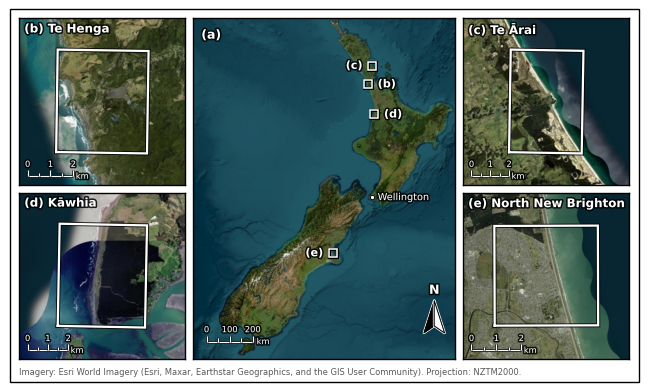

In [4]:
# =====================================================================================
# Training site figure: NZ context map + one satellite-imagery map per classifier training site
# =====================================================================================
# (a) New Zealand, with a labelled marker at each training site
# (b)-(e) Each site: the training area (the image extent labelled for classifier training) on
#         satellite imagery, with the surrounding coast
# Layout: west-coast sites on the left of the context map, east-coast sites on the right.
#
# The training areas are read from the SITES dictionary (bbox entries) in Section 1 of
# train_new_classifier_veg_NZ.ipynb, so they match what you labelled. If the notebook can't be
# found, the approximate boxes in FALLBACK_BBOX are used instead and a warning is printed.
#
# Basemap: Esri World Imagery by default, or LINZ Basemaps aerial imagery with a LINZ API key.
# Everything is drawn in NZTM2000 (EPSG:2193). Needs: matplotlib, pyproj, contextily, internet.
# Saves training_sites.png and training_sites.pdf to OUT.

import os, glob, json, ast
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from pyproj import Transformer
import contextily as ctx

# ---------------- EDIT ME ----------------
CG_CANDIDATES = [   # COASTGUARD-master folder; the first that exists is used
    r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master',
    '/Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master',
]
CG = next((p for p in CG_CANDIDATES if os.path.isdir(p)), CG_CANDIDATES[0])
TRAIN_NB = os.path.join(CG, 'Classification', 'train_new_classifier_veg_NZ.ipynb')   # searched for if not here
OUT = os.path.join(CG, 'Data', 'Figures')

# Training sites: key as in the notebook's SITES, display name, and panel position.
#   side  'left' or 'right' of the context map;  row  0 = top, 1 = bottom
#   Panels are lettered across each row: top-left (b), top-right (c), bottom-left (d), bottom-right (e)
TRAIN_SITES = {
    'TeHenga':          {'name': 'Te Henga',           'side': 'left',  'row': 0},
    'TeArai':           {'name': 'Te Ārai',            'side': 'right', 'row': 0},
    'Kawhia':           {'name': 'Kāwhia',             'side': 'left',  'row': 1},
    'NorthNewBrighton': {'name': 'North New Brighton', 'side': 'right', 'row': 1},
}
# APPROXIMATE boxes (lonmin, lonmax, latmin, latmax), only used if the notebook can't be read.
# Replace with the bbox values from Section 1 if you see the fallback warning.
FALLBACK_BBOX = {
    'TeHenga':          (174.425, 174.460, -36.905, -36.875),
    'TeArai':           (174.620, 174.670, -36.160, -36.110),
    'Kawhia':           (174.760, 174.800, -38.120, -38.070),
    'NorthNewBrighton': (172.715, 172.745, -43.500, -43.465),
}

# Context map extent (lon_min, lat_min, lon_max, lat_max): mainland New Zealand
CONTEXT = (166.2, -47.4, 178.5, -34.2)   # keep lon_max <= ~178.5: further east, a corner crosses 180°
PLACES = {'Auckland': (-36.848, 174.763), 'Wellington': (-41.287, 174.776)}
# name: (lat, lon); {} for none. Places near an edge or a training site are skipped

SITE_ZOOM_OUT = 1.6  # site map size = this x the training area's longest side (more = more surroundings)
SITE_ASPECT = 1.0    # site panel height / width (1 = square)
CONTEXT_LABELS = 'letter'  # beside each context box: 'letter' = (b), 'name' = (b) Te Henga, None = off
#                            (full names crowd each other at the scale of the whole country)
BORDER = 1.0         # pt; border around each map and around the whole figure (0 for none)
LINE_COL = 'white'   # training-area outline (white with a black edge, as the NZCCD line in the validation figure)

BASEMAP = 'esri'     # 'esri' or 'linz'
# LINZ: open basemaps.linz.govt.nz, use the menu to copy the aerial XYZ tile URL, and paste it here
# (it contains your API key), e.g. 'https://basemaps.linz.govt.nz/v1/tiles/aerial/3857/{z}/{x}/{y}.webp?api=c01...'
LINZ_URL = ''
ZOOM = {'context': 7, 'site': 14}   # tile levels; Esri switches to sharper NZ aerial photos from about 14
MAX_ZOOM = 17

FIG_WIDTH = 6.3      # in (16 cm)
DPI = 300
FONT = 8
# ------------------------------------------

HALO = [pe.withStroke(linewidth=2.2, foreground='black', alpha=0.85)]
TO_NZTM = Transformer.from_crs(4326, 2193, always_xy=True)
TO_LL = Transformer.from_crs(2193, 4326, always_xy=True)
plt.rcParams.update({'font.size': FONT, 'font.family': 'sans-serif'})

if BASEMAP == 'linz':
    if not LINZ_URL:
        raise ValueError('Paste the LINZ aerial tile URL into LINZ_URL, or set BASEMAP = "esri".')
    SOURCE = LINZ_URL
    CREDIT = 'Imagery: LINZ Basemaps aerial imagery (CC BY 4.0). Projection: NZTM2000.'
else:
    SOURCE = ctx.providers.Esri.WorldImagery
    CREDIT = ('Imagery: Esri World Imagery (Esri, Maxar, Earthstar Geographics, and the GIS User Community). '
              'Projection: NZTM2000.')


# ---------------- training areas from the notebook ----------------
def find_notebook():
    if os.path.isfile(TRAIN_NB):
        return TRAIN_NB
    hits = sorted(glob.glob(os.path.join(CG, '**', 'train_new_classifier_veg_NZ*.ipynb'), recursive=True))
    hits = [h for h in hits if '.ipynb_checkpoints' not in h]
    return hits[0] if hits else None


def bboxes_from_notebook(path):
    '''Read each site's bbox from the SITES = {...} assignment in the notebook, without running it.'''
    with open(path, encoding='utf-8') as f:
        nb = json.load(f)
    for cell in nb.get('cells', []):
        if cell.get('cell_type') != 'code':
            continue
        src = ''.join(cell.get('source', []))
        if 'SITES' not in src:
            continue
        src = '\n'.join(l for l in src.split('\n') if not l.lstrip().startswith(('%', '!')))
        try:
            tree = ast.parse(src)
        except SyntaxError:
            continue
        for node in tree.body:
            if (isinstance(node, ast.Assign) and isinstance(node.value, ast.Dict)
                    and any(isinstance(t, ast.Name) and t.id == 'SITES' for t in node.targets)):
                out = {}
                for k, v in zip(node.value.keys, node.value.values):
                    if not (isinstance(k, ast.Constant) and isinstance(v, ast.Dict)):
                        continue
                    entry = {}
                    for kk, vv in zip(v.keys, v.values):
                        if isinstance(kk, ast.Constant) and kk.value in ('bbox', 'role'):
                            try:
                                entry[kk.value] = ast.literal_eval(vv)
                            except ValueError:
                                pass
                    out[k.value] = entry
                return out
    return None


nb_path = find_notebook()
nb_sites = bboxes_from_notebook(nb_path) if nb_path else None
BBOX = {}
for key in TRAIN_SITES:
    b = (nb_sites or {}).get(key, {}).get('bbox')
    if b and len(b) == 4:
        BBOX[key] = tuple(b)
    else:
        BBOX[key] = FALLBACK_BBOX[key]
        print(f'Warning: no bbox for {key} in the training notebook '
              f'({"not found" if not nb_path else os.path.basename(nb_path)}); using the APPROXIMATE fallback box')
if nb_path and nb_sites:
    print('Training areas read from', nb_path)


# ---------------- helpers (same style as the validation figure) ----------------
def fit_aspect(b, aspect, min_w=0):
    cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
    w = max(b[2] - b[0], (b[3] - b[1]) / aspect, min_w)
    h = w * aspect
    return (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)


def nice(x):
    e = 10 ** np.floor(np.log10(x))
    return next(m * e for m in (5, 2, 1) if m * e <= x)


def ax_size_in(ax):
    b = ax.get_position()
    w, h = ax.figure.get_size_inches()
    return b.width * w, b.height * h


def scalebar(ax, frac=0.3, x=0.05, y=0.05):
    '''Esri "Scale Line 1" style.'''
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    L = nice((x1 - x0) * frac)
    bx, by = x0 + x * (x1 - x0), y0 + y * (y1 - y0)
    _, h_in = ax_size_in(ax)
    big, small = 0.06 / h_in * (y1 - y0), 0.035 / h_in * (y1 - y0)
    halo = [pe.withStroke(linewidth=2.2, foreground='black', alpha=0.85)]
    kw = dict(color='white', lw=0.9, solid_capstyle='butt', zorder=6, path_effects=halo)
    ax.plot([bx, bx + L], [by, by], **kw)
    for t in (0, 0.25, 0.5, 0.75, 1):
        ax.plot([bx + t * L] * 2, [by, by + (big if t in (0, 0.5, 1) else small)], **kw)
    unit, k = ('km', 1000) if L >= 1000 else ('m', 1)
    for t in (0, 0.5, 1):
        ax.text(bx + t * L, by + big * 1.25, f'{t * L / k:g}', ha='center', va='bottom', color='white',
                fontsize=FONT - 2, path_effects=HALO, zorder=6)
    ax.text(bx + L + 0.015 * (x1 - x0), by, unit, ha='left', va='center', color='white',
            fontsize=FONT - 2, path_effects=HALO, zorder=6)


def north_arrow(ax, x=0.10, y=0.92, size=0.32):
    '''ArcGIS "North 3" style split arrowhead; x, y = tip (axes fraction), size in inches.'''
    w_in, h_in = ax_size_in(ax)
    hy, hx = size / h_in, 0.32 * size / w_in
    notch = 0.22 * hy
    tip, base_c = (x, y), (x, y - hy + notch)
    halo = [pe.withStroke(linewidth=2.0, foreground='white', alpha=0.9)]
    for pts, fc in (([tip, (x - hx, y - hy), base_c], 'black'), ([tip, (x + hx, y - hy), base_c], 'white')):
        p = plt.Polygon(pts, closed=True, fc=fc, ec='black', lw=0.6, joinstyle='round',
                        transform=ax.transAxes, zorder=6)
        p.set_path_effects(halo + [pe.Normal()])
        ax.add_patch(p)
    ax.text(x, y + 0.012, 'N', transform=ax.transAxes, ha='center', va='bottom', color='white',
            fontsize=FONT + 1, fontweight='bold', path_effects=HALO, zorder=6)


def panel_label(ax, text, size=FONT + 1):
    return ax.text(0.03, 0.97, text, transform=ax.transAxes, ha='left', va='top', color='white',
                   fontsize=size, fontweight='bold', path_effects=HALO, zorder=7)


def style(ax, ext):
    ax.set_xlim(ext[0], ext[2]); ax.set_ylim(ext[1], ext[3])
    ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_linewidth(BORDER); s.set_color('black'); s.set_zorder(10); s.set_visible(BORDER > 0)


def tile_zoom(ext, width_in, setting):
    if setting != 'auto':
        return setting
    lon0, _ = TO_LL.transform(ext[0], (ext[1] + ext[3]) / 2)
    lon1, _ = TO_LL.transform(ext[2], (ext[1] + ext[3]) / 2)
    z = int(np.ceil(np.log2(DPI * width_in * 360 / (256 * abs(lon1 - lon0)))))
    return int(np.clip(z, 1, MAX_ZOOM))


def add_imagery(ax, ext, zoom):
    '''Fetch tiles for an NZTM extent and draw them, reprojected to NZTM.
    Done here rather than with ctx.add_basemap so the request box never wraps across 180°
    (a wrapped box makes contextily download tiles for the whole way round the globe).'''
    k = 25
    xs = np.r_[np.linspace(ext[0], ext[2], k), np.full(k, ext[2]),
               np.linspace(ext[2], ext[0], k), np.full(k, ext[0])]
    ys = np.r_[np.full(k, ext[1]), np.linspace(ext[1], ext[3], k),
               np.full(k, ext[3]), np.linspace(ext[3], ext[1], k)]
    lon, lat = (np.asarray(v) for v in TO_LL.transform(xs, ys))
    lon = np.where(lon < 0, lon + 360, lon)            # NZ side of 180°: -179.9 -> 180.1
    w, e = lon.min(), min(lon.max(), 179.999)
    s, n = lat.min(), lat.max()
    try:
        img, bb = ctx.bounds2img(w, s, e, n, zoom=zoom, source=SOURCE, ll=True, n_connections=4)
    except TypeError:                                   # older contextily: no parallel downloads
        img, bb = ctx.bounds2img(w, s, e, n, zoom=zoom, source=SOURCE, ll=True)
    img, bb = ctx.warp_tiles(img, bb, t_crs='EPSG:2193')
    ax.imshow(img, extent=bb, interpolation='bilinear', zorder=0)
    ax.set_xlim(ext[0], ext[2]); ax.set_ylim(ext[1], ext[3])


def to_nztm_box(lonmin, lonmax, latmin, latmax):
    xs, ys = TO_NZTM.transform([lonmin, lonmax, lonmin, lonmax], [latmin, latmin, latmax, latmax])
    return (min(xs), min(ys), max(xs), max(ys))


# ---------------- extents ----------------
site_data = {}
for key, cfg in TRAIN_SITES.items():
    aoi = to_nztm_box(*BBOX[key])          # the AOI is a lat/lon box, so slightly skewed in NZTM
    lon0, lon1, lat0, lat1 = BBOX[key]
    corners = np.array(TO_NZTM.transform([lon0, lon1, lon1, lon0, lon0], [lat0, lat0, lat1, lat1, lat0])).T
    side = max(aoi[2] - aoi[0], aoi[3] - aoi[1]) * SITE_ZOOM_OUT
    ext = fit_aspect(aoi, SITE_ASPECT, min_w=side)
    site_data[key] = dict(cfg, aoi=aoi, corners=corners, ext=ext,
                          centre=((aoi[0] + aoi[2]) / 2, (aoi[1] + aoi[3]) / 2))
    print(f'{cfg["name"]}: training area {(aoi[2] - aoi[0]) / 1000:.1f} x {(aoi[3] - aoi[1]) / 1000:.1f} km')

cext = to_nztm_box(CONTEXT[0], CONTEXT[2], CONTEXT[1], CONTEXT[3])

# ---- layout (inches): left column | context map | right column; columns match the map's height ----
M, G, LEG = 0.10, 0.08, 0.24     # LEG = strip below the maps for the imagery credit
rows = 1 + max(d['row'] for d in site_data.values())
ra = (cext[3] - cext[1]) / (cext[2] - cext[0])
avail = FIG_WIDTH - 2 * M - 2 * G
s = SITE_ASPECT
wR = (avail - (rows - 1) * G / ra) / (2 + rows * s / ra)
wA = (rows * s * wR + (rows - 1) * G) / ra
hA, hR = ra * wA, s * wR
FH = LEG + hA + M
fig = plt.figure(figsize=(FIG_WIDTH, FH))
F = lambda x, y, w, h: [x / FIG_WIDTH, y / FH, w / FIG_WIDTH, h / FH]
axA = fig.add_axes(F(M + wR + G, LEG, wA, hA))
for d in site_data.values():
    x = M if d['side'] == 'left' else M + wR + G + wA + G
    d['ax'] = fig.add_axes(F(x, LEG + (rows - 1 - d['row']) * (hR + G), wR, hR))

# panel letters across each row: left then right
order = sorted(site_data, key=lambda k: (site_data[k]['row'], site_data[k]['side'] != 'left'))
for i, k in enumerate(order):
    site_data[k]['letter'] = 'bcdefghij'[i]

# ---- (a) context map ----
style(axA, cext)
import time; _t = time.time()
print('downloading context imagery...', flush=True)
add_imagery(axA, cext, tile_zoom(cext, wA, ZOOM['context']))
print(f'  done in {time.time() - _t:.0f} s', flush=True)
BOX_PT = 6          # context box size in points (training areas are far too small to show to scale)
for d in site_data.values():
    axA.plot(*d['centre'], 's', ms=BOX_PT, mfc='none', mec='black', mew=2.2, zorder=6)
    axA.plot(*d['centre'], 's', ms=BOX_PT, mfc='none', mec='white', mew=1.1, zorder=7)
    if CONTEXT_LABELS:   # on the side away from the site's panel
        right = d['side'] == 'left'
        txt = f'({d["letter"]})' + (f' {d["name"]}' if CONTEXT_LABELS == 'name' else '')
        axA.annotate(txt, d['centre'], xytext=(7 if right else -7, 0),
                     textcoords='offset points', ha='left' if right else 'right', va='center',
                     color='white', fontsize=FONT, fontweight='bold', path_effects=HALO, zorder=8)
W_A = cext[2] - cext[0]
for place, (lat, lon) in PLACES.items():
    px, py = TO_NZTM.transform(lon, lat)
    fx, fy = (px - cext[0]) / W_A, (py - cext[1]) / (cext[3] - cext[1])
    near = any(np.hypot(px - d['centre'][0], py - d['centre'][1]) < 0.06 * W_A for d in site_data.values())
    if near or not (0.03 < fx < 0.8 and 0.05 < fy < 0.95):
        continue
    axA.plot(px, py, 'o', ms=3, mfc='white', mec='black', mew=0.6, zorder=5)
    axA.text(px + 0.02 * W_A, py, place, ha='left', va='center', color='white',
             fontsize=FONT - 1, path_effects=HALO, zorder=6)
panel_label(axA, '(a)')
scalebar(axA, frac=0.35)
north_arrow(axA, x=0.92, y=0.17)   # tip position (axes fraction); open Pacific

# ---- site maps ----
for k, d in site_data.items():
    ax = d['ax']
    style(ax, d['ext'])
    z = tile_zoom(d['ext'], wR, ZOOM['site'])
    print(f'{d["name"]}: tile level {z}')
    add_imagery(ax, d['ext'], z)
    ax.plot(*d['corners'].T, color=LINE_COL, lw=1.6, solid_joinstyle='miter', zorder=5,
            path_effects=[pe.withStroke(linewidth=3.0, foreground='black', alpha=0.8)])
    d['label'] = panel_label(ax, f'({d["letter"]}) {d["name"]}')
    scalebar(ax, frac=0.35)

# ---- legend, credit, border ----
# site labels: one size for all panels, the validation figure's size unless a name won't fit
r = fig.canvas.get_renderer()
fits = min((d['ax'].get_window_extent(r).width * 0.94) / d['label'].get_window_extent(r).width
           for d in site_data.values())
if fits < 1:
    for d in site_data.values():
        d['label'].set_fontsize((FONT + 1) * fits)
if BORDER > 0:
    inset = BORDER / 72 / 2
    fig.add_artist(Rectangle((inset / FIG_WIDTH, inset / FH), 1 - 2 * inset / FIG_WIDTH,
                             1 - 2 * inset / FH, transform=fig.transFigure, fill=False,
                             ec='black', lw=BORDER, zorder=20))
fig.text(M / FIG_WIDTH, 0.07 / FH, CREDIT, fontsize=FONT - 2, color='0.35', va='bottom')

os.makedirs(OUT, exist_ok=True)
for ext_ in ('png', 'pdf'):
    fig.savefig(os.path.join(OUT, f'training_sites.{ext_}'), dpi=DPI)
print('Saved to', OUT)
plt.show()